# Analisis Komparasi Hasil Deteksi Multi-Objek Model YOLOv8 Pre-trained Menggunakan Variasi Confidence Threshold

| | |
|---|---|
| **Nama** | Nadhif Rif'at Rasendriya |
| **NIM** | 235150201111074 |
| **Program Studi** | Teknik Informatika, FILKOM, Universitas Brawijaya |
| **Mata Kuliah** | CIF61339 - Pengolahan Citra Digital dan Visi Komputer |
| **Tanggal** | 28 Oktober 2026 |

## Tujuan dan pemetaan ketentuan tugas

Mengimplementasikan model YOLO pre-trained untuk mendeteksi objek pada beberapa gambar, lalu menganalisis hasilnya. Fokus analisis: **bagaimana confidence threshold 0,25 vs 0,60 mengubah hasil deteksi**.

| No | Ketentuan dari slide | Dipenuhi di |
|---|---|---|
| 1 | Gunakan Google Colab | Seluruh notebook |
| 2 | Gunakan model YOLO pre-trained (`yolov8n.pt`) | Step 4 |
| 3 | 5 gambar berbeda, diambil sendiri dengan kamera HP, sebaiknya >1 objek per gambar | Step 3 (**lihat peringatan di bawah**) |
| 4 | Jalankan deteksi pada kelima gambar | Step 5 |
| 5 | Tampilkan gambar asli + hasil (bounding box, nama kelas, confidence score) | Step 6 |
| 6 | Dua nilai confidence threshold: 0,25 dan 0,60 | Step 5 |
| 7 | Bandingkan hasil kedua percobaan | Step 7-11 |

> **PERINGATAN KETENTUAN POIN 3.** Slide meminta gambar **diambil sendiri menggunakan kamera HP**. Versi dataset awal notebook ini memakai gambar dari internet (COCO dan Unsplash). Sebelum dikumpulkan, ganti dengan 5 foto sendiri: set `MODE_SUMBER = "upload"` di Step 3, kecuali dosen sudah mengizinkan gambar dari internet secara tertulis.

## Step 1 - Setup lingkungan

Instal library **Ultralytics** (implementasi resmi YOLOv8) dan impor library pendukung. Runtime GPU (T4) opsional, karena `yolov8n` cukup ringan dijalankan di CPU untuk 5 gambar.

In [37]:
!pip -q install ultralytics

import os, glob, time, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
import ultralytics
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

warnings.filterwarnings("ignore")

print("Ultralytics :", ultralytics.__version__)
print("PyTorch     :", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

Ultralytics : 8.4.191
PyTorch     : 2.11.0+cu130
GPU tersedia: True


## Step 2 - Konfigurasi eksperimen

Semua parameter dikumpulkan di satu tempat supaya eksperimen **reproducible** dan mudah dilaporkan. Hanya `conf` yang divariasikan; `iou` (NMS) dan `imgsz` dikunci agar perbedaan hasil benar-benar berasal dari confidence threshold.

In [38]:
NAMA = "Nadhif Rif'at Rasendriya"
NIM = "235150201111074"

MODEL_NAME = "yolov8n.pt"
THRESHOLDS = [0.25, 0.60]
IOU_NMS = 0.7                   # (default Ultralytics)
IMGSZ = 640                     # (default Ultralytics)

IMG_DIR = "dataset"
OUT_DIR = "hasil_deteksi"

os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True)

print(f"{NAMA} | NIM {NIM}")
print(f"Model={MODEL_NAME}  conf={THRESHOLDS}  iou={IOU_NMS}  imgsz={IMGSZ}")

Nadhif Rif'at Rasendriya | NIM 235150201111074
Model=yolov8n.pt  conf=[0.25, 0.6]  iou=0.7  imgsz=640


## Step 3 - Persiapan dataset (5 gambar)

### 3.1 Sumber gambar

| File | Skenario | URL langsung | Asal |
|---|---|---|---|
| `gambar1.jpg` | Dapur dan aktivitas memasak | http://images.cocodataset.org/val2017/000000397133.jpg | COCO val2017, id 397133 |
| `gambar2.jpg` | Dua kucing di sofa | http://images.cocodataset.org/val2017/000000039769.jpg | COCO val2017, id 39769 |
| `gambar3.jpg` | Jalanan kota saat senja | https://images.unsplash.com/photo-1458169495136-854e4c39548a | Unsplash |
| `gambar4.jpg` | Meja kerja dengan laptop | https://images.unsplash.com/photo-1498050108023-c5249f4df085 | Unsplash |
| `gambar5.jpg` | Lapangan bisbol | http://images.cocodataset.org/train2017/000000411975.jpg | COCO **train2017**, id 411975 |

[OK]    gambar1.jpg
[OK]    gambar2.jpg
[OK]    gambar3.jpg
[OK]    gambar4.jpg
[OK]    gambar5.jpg

gambar1.jpg  640x427 px  196 KB
gambar2.jpg  640x480 px  169 KB
gambar3.jpg  1280x853 px  137 KB
gambar4.jpg  1280x852 px  136 KB
gambar5.jpg  500x375 px  110 KB


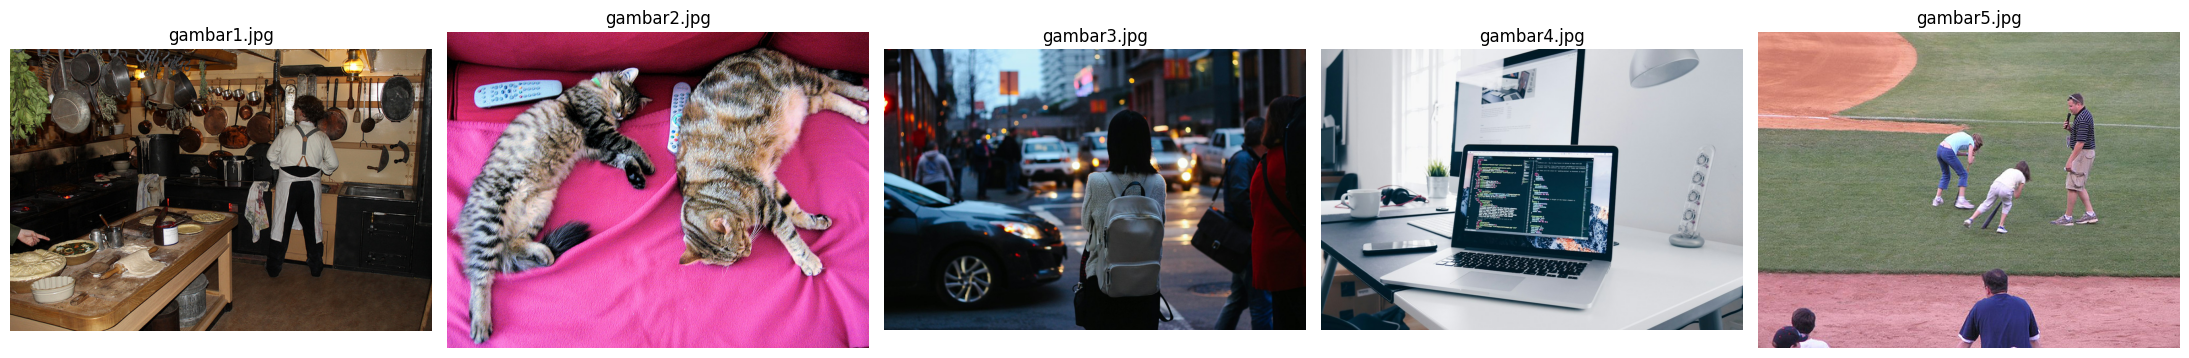

In [39]:
URL_GAMBAR = {
    "gambar1.jpg": "http://images.cocodataset.org/val2017/000000397133.jpg",
    "gambar2.jpg": "http://images.cocodataset.org/val2017/000000039769.jpg",
    "gambar3.jpg": "https://images.unsplash.com/photo-1458169495136-854e4c39548a",
    "gambar4.jpg": "https://images.unsplash.com/photo-1498050108023-c5249f4df085",
    "gambar5.jpg": "http://images.cocodataset.org/train2017/000000411975.jpg",
}

MODE_SUMBER = "url"

HEADERS = {"User-Agent": "Mozilla/5.0 (tugas-PCD-FILKOM-UB)"}


def build_url(url):
    if "unsplash.com" in url and "?" not in url:
        return url + "?auto=format&fit=crop&w=1280&q=80"
    return url


def unduh(nama, url):
    path = os.path.join(IMG_DIR, nama)
    try:
        r = requests.get(build_url(url), headers=HEADERS, timeout=30)
        r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
        Image.open(path).verify()
        print(f"[OK]    {nama}")
        return True
    except Exception as e:
        print(f"[GAGAL] {nama}: {e}")
        if os.path.exists(path):
            os.remove(path)
        return False


if MODE_SUMBER == "url":
    perlu_upload = [n for n, u in URL_GAMBAR.items() if not unduh(n, u)]
else:
    perlu_upload = list(URL_GAMBAR.keys())

if perlu_upload:
    from google.colab import files
    print(f"\nUnggah {len(perlu_upload)} berkas. Dipetakan sesuai urutan nama berkas:")
    up = files.upload()
    for target, asal in zip(perlu_upload, sorted(up.keys())):
        with open(os.path.join(IMG_DIR, target), "wb") as f:
            f.write(up[asal])
        print(f"  {asal}  ->  {target}")

daftar_gambar = sorted(glob.glob(os.path.join(IMG_DIR, "gambar*.jpg")))
assert len(daftar_gambar) == 5, f"Dibutuhkan 5 gambar, ditemukan {len(daftar_gambar)}"

print()
for p in daftar_gambar:
    im = Image.open(p)
    print(f"{os.path.basename(p):12s} {im.size[0]}x{im.size[1]} px  {os.path.getsize(p)/1024:.0f} KB")

fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for a, p in zip(ax, daftar_gambar):
    a.imshow(Image.open(p).convert("RGB"))
    a.set_title(os.path.basename(p))
    a.axis("off")
plt.tight_layout()
plt.show()

### 3.4 Ground truth manual (estimasi objek sebenarnya per gambar)


In [40]:
GROUND_TRUTH = {
    "gambar1.jpg": {"person": 1, "oven": 1, "sink": 1, "dining table": 1, "bowl": 3, "cup": 1},
    "gambar2.jpg": {"cat": 2, "couch": 1, "remote": 2},
    "gambar3.jpg": {"person": 7, "car": 5, "backpack": 1, "handbag": 1, "traffic light": 1},
    "gambar4.jpg": {"laptop": 1, "tv": 1, "keyboard": 2, "cell phone": 1, "cup": 1, "potted plant": 1},
    # "gambar4.jpg": {"laptop": 1, "tv": 1, "keyboard": 2, "cell phone": 1, "cup": 1, "potted plant": 1, "extension reel": 1},
    "gambar5.jpg": {"person": 6},
}

for k, v in GROUND_TRUTH.items():
    print(f"{k:12s} total objek: {sum(v.values()):2d}  {v}")

gambar1.jpg  total objek:  8  {'person': 1, 'oven': 1, 'sink': 1, 'dining table': 1, 'bowl': 3, 'cup': 1}
gambar2.jpg  total objek:  5  {'cat': 2, 'couch': 1, 'remote': 2}
gambar3.jpg  total objek: 15  {'person': 7, 'car': 5, 'backpack': 1, 'handbag': 1, 'traffic light': 1}
gambar4.jpg  total objek:  7  {'laptop': 1, 'tv': 1, 'keyboard': 2, 'phone': 1, 'cup': 1, 'potted plant': 1}
gambar5.jpg  total objek:  6  {'person': 6}


## Step 4 - Muat model YOLO pre-trained


In [41]:
model = YOLO(MODEL_NAME)

print("Jumlah kelas :", len(model.names))
print("Contoh kelas :", [model.names[i] for i in range(0, 80, 8)], "...")

nama_kelas = set(model.names.values())
for g, d in GROUND_TRUTH.items():
    tak_dikenal = [k for k in d if k not in nama_kelas]
    if tak_dikenal:
        print(f"[PERIKSA] {g}: kelas {tak_dikenal} tidak ada di COCO-80")

Jumlah kelas : 80
Contoh kelas : ['person', 'boat', 'dog', 'backpack', 'sports ball', 'wine glass', 'sandwich', 'chair', 'mouse', 'refrigerator'] ...
[PERIKSA] gambar4.jpg: kelas ['phone'] tidak ada di COCO-80


## Step 5 - Jalankan deteksi dengan dua confidence threshold


In [42]:
hasil = {}
waktu = {}

for thr in THRESHOLDS:
    tag = f"conf{int(round(thr * 100)):03d}"
    t0 = time.time()
    res = model.predict(
        source=daftar_gambar,
        conf=thr,
        iou=IOU_NMS,
        imgsz=IMGSZ,
        save=True,
        project=OUT_DIR,
        name=tag,
        exist_ok=True,
        verbose=False,
    )
    waktu[thr] = time.time() - t0
    hasil[thr] = {os.path.basename(r.path): r for r in res}
    print(f"conf={thr:.2f} -> folder '{OUT_DIR}/{tag}' | {sum(len(r.boxes) for r in res)} deteksi total | {waktu[thr]:.1f} dtk")

Results saved to /content/runs/detect/hasil_deteksi/conf025
conf=0.25 -> folder 'hasil_deteksi/conf025' | 48 deteksi total | 0.3 dtk
Results saved to /content/runs/detect/hasil_deteksi/conf060
conf=0.60 -> folder 'hasil_deteksi/conf060' | 25 deteksi total | 0.1 dtk


## Step 6 - Visualisasi: gambar asli vs hasil deteksi

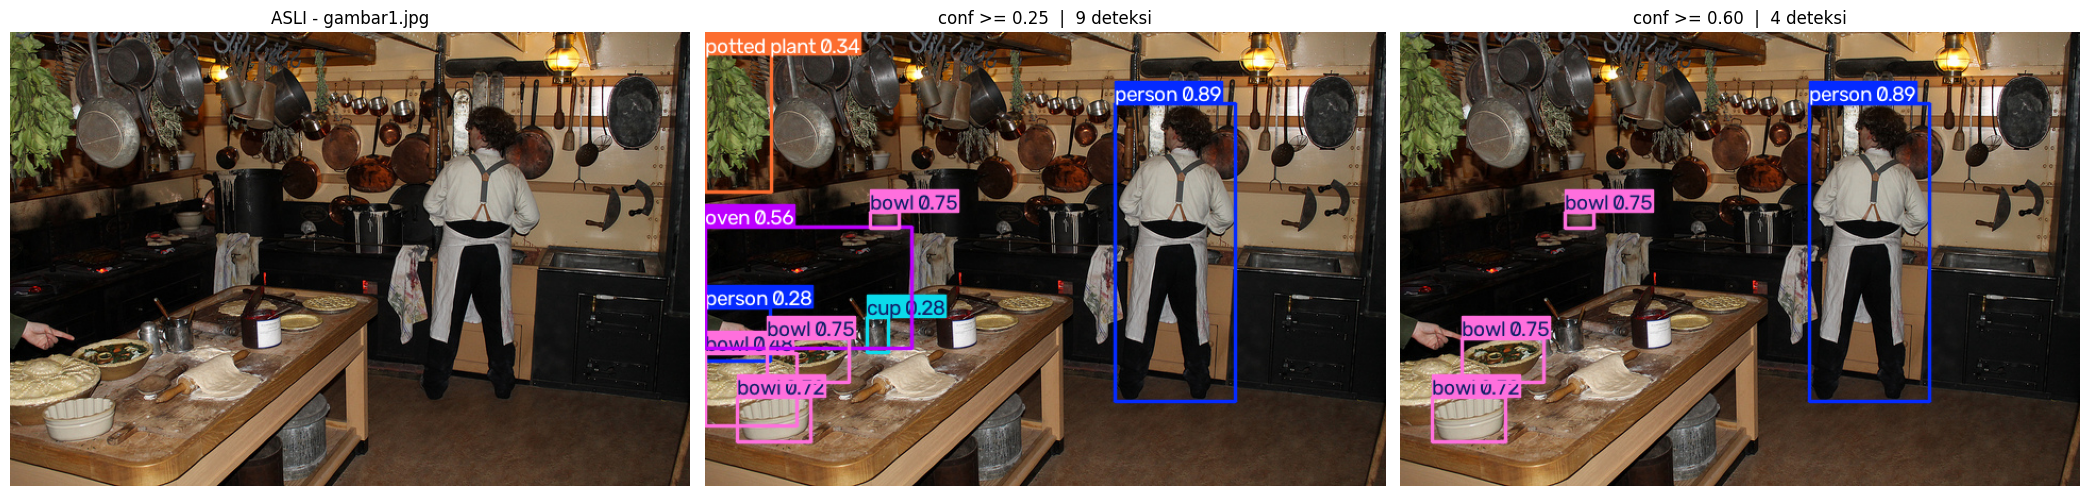

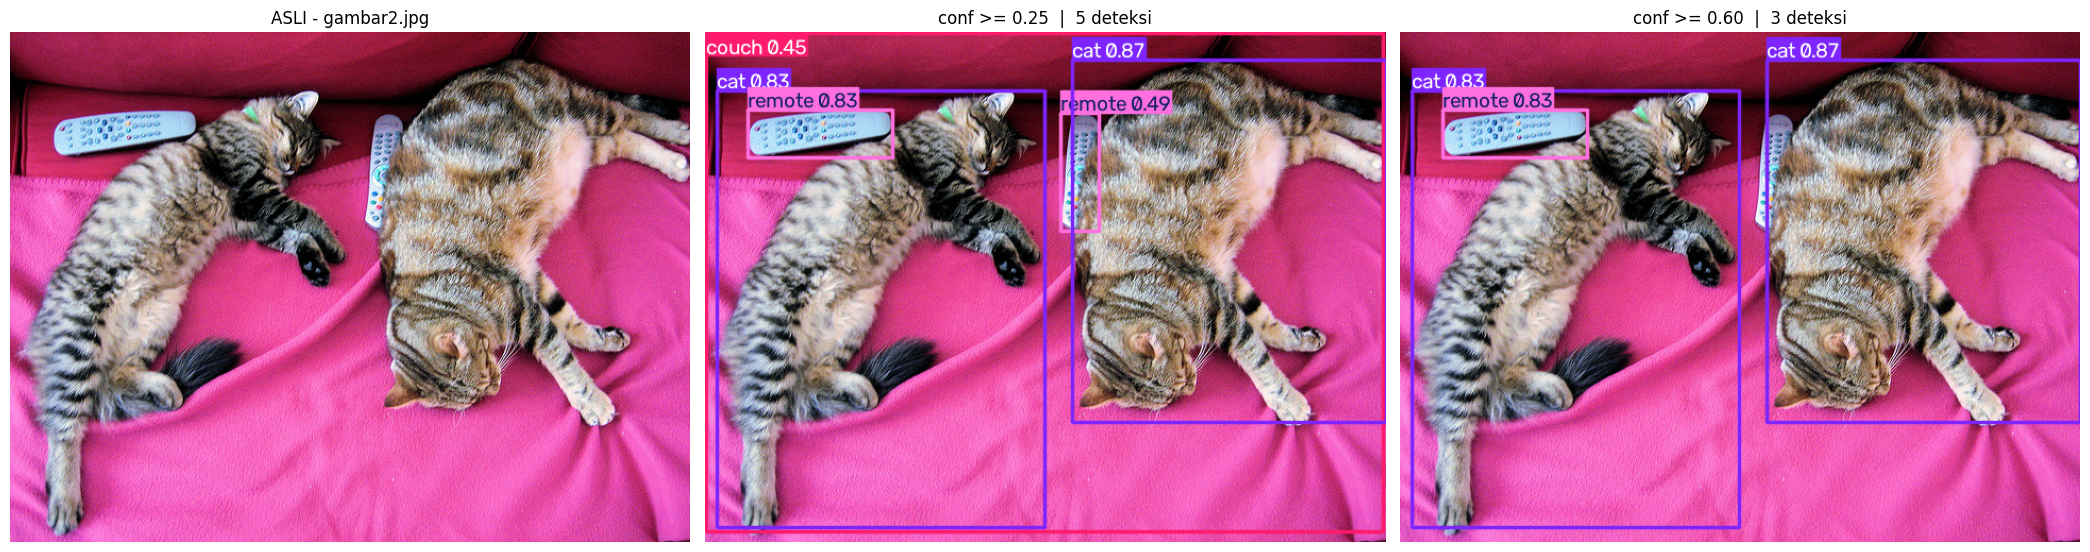

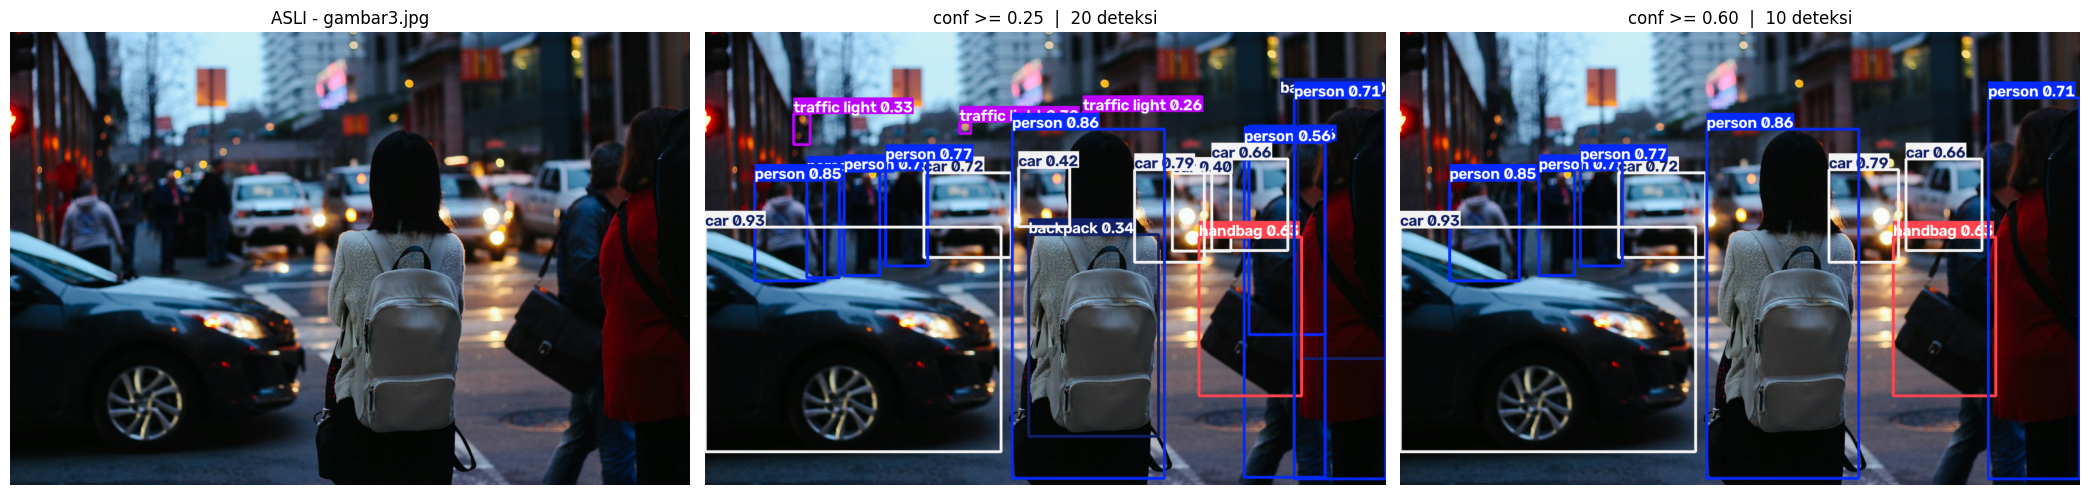

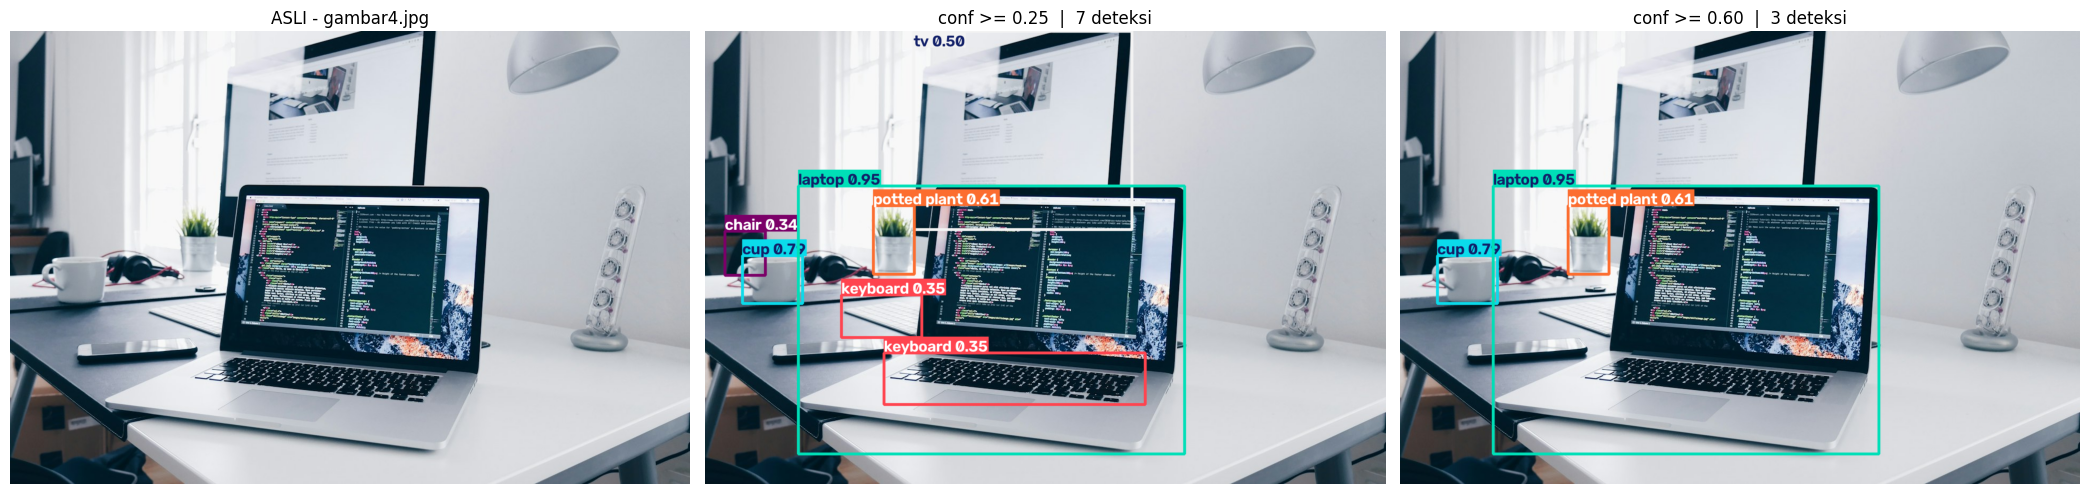

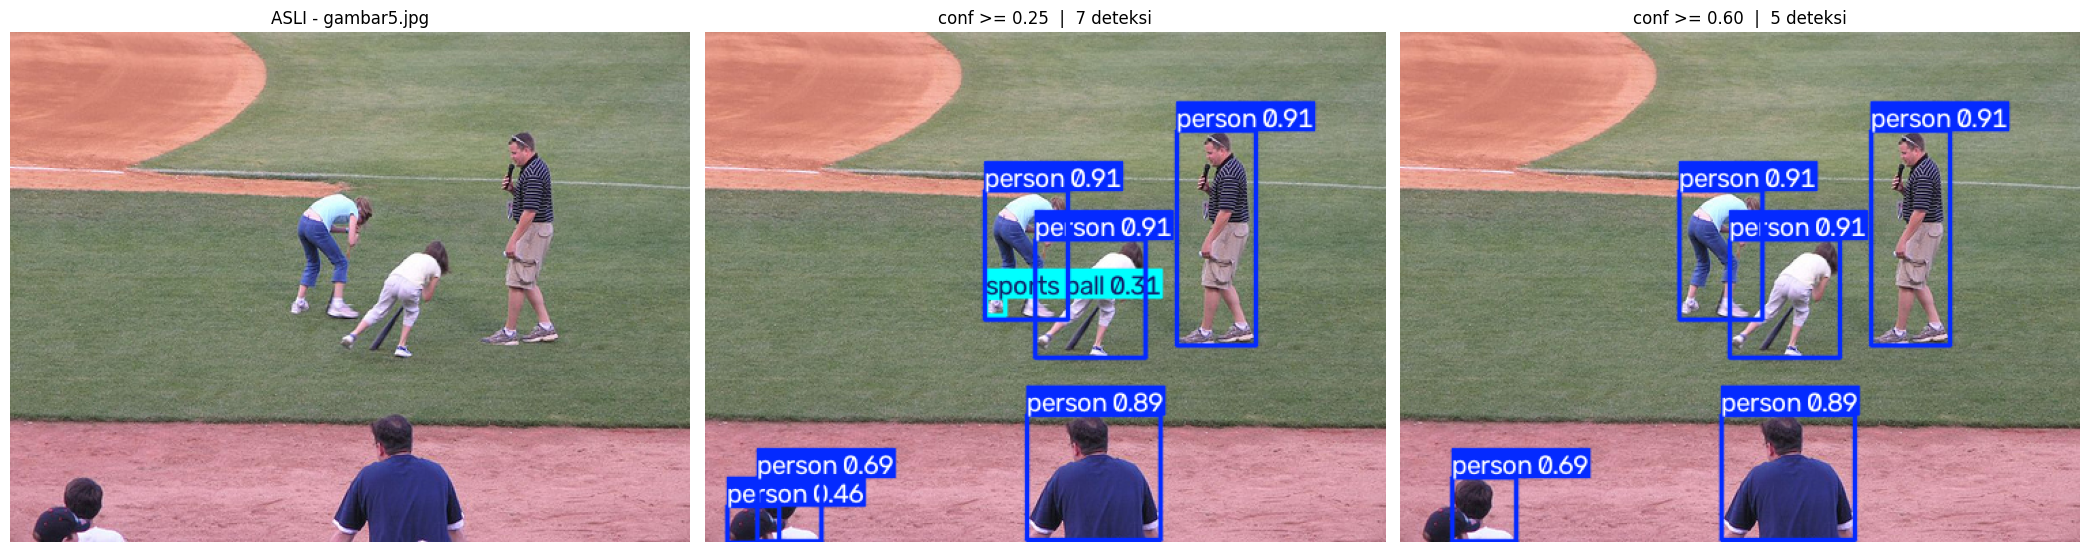

In [43]:
def tampil_perbandingan(nama):
    asli = Image.open(os.path.join(IMG_DIR, nama)).convert("RGB")
    n_kolom = 1 + len(THRESHOLDS)
    fig, ax = plt.subplots(1, n_kolom, figsize=(7 * n_kolom, 6))
    ax[0].imshow(asli)
    ax[0].set_title(f"ASLI - {nama}", fontsize=12)
    for i, thr in enumerate(THRESHOLDS, start=1):
        r = hasil[thr][nama]
        ax[i].imshow(r.plot()[..., ::-1])
        ax[i].set_title(f"conf >= {thr:.2f}  |  {len(r.boxes)} deteksi", fontsize=12)
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", f"perbandingan_{nama.replace('.jpg', '')}.png"), dpi=130)
    plt.show()


for nama in sorted(hasil[THRESHOLDS[0]].keys()):
    tampil_perbandingan(nama)

## Step 7 - Tabel detail seluruh deteksi

In [44]:
kolom = ["gambar", "threshold", "kelas", "conf", "x1", "y1", "x2", "y2"]
baris = []
for thr, per_gambar in hasil.items():
    for nama, r in per_gambar.items():
        for b in r.boxes:
            x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
            baris.append({
                "gambar": nama,
                "threshold": thr,
                "kelas": model.names[int(b.cls.item())],
                "conf": round(float(b.conf.item()), 3),
                "x1": round(x1), "y1": round(y1), "x2": round(x2), "y2": round(y2),
            })

df = pd.DataFrame(baris, columns=kolom)
print("Jumlah baris per threshold:")
print(df.groupby("threshold").size().to_string())

df_tampil = df.sort_values(["gambar", "threshold", "conf"], ascending=[True, True, False])
display(df_tampil.reset_index(drop=True))

Jumlah baris per threshold:
threshold
0.25    48
0.60    25


,gambar,threshold,kelas,conf,x1,y1,x2,y2
0,gambar1.jpg,0.25,person,0.894,385,68,499,348
1,gambar1.jpg,0.25,bowl,0.747,58,289,136,329
2,gambar1.jpg,0.25,bowl,0.745,155,169,182,185
3,gambar1.jpg,0.25,bowl,0.725,31,343,100,386
4,gambar1.jpg,0.25,oven,0.563,0,183,195,298
...,...,...,...,...,...,...,...,...
68,gambar5.jpg,0.60,person,0.913,206,116,267,212
69,gambar5.jpg,0.60,person,0.910,346,73,404,231
70,gambar5.jpg,0.60,person,0.907,242,153,324,240
71,gambar5.jpg,0.60,person,0.889,236,281,335,374


## Step 8 - Perbandingan kuantitatif per gambar

TOTAL: 48 deteksi @0.25  ->  25 deteksi @0.6  (23 hilang, 47.9%)



,Gambar,Deteksi @0.25,Deteksi @0.6,Hilang,% Hilang,Rata2 conf @0.25,Rata2 conf @0.6,Kelas yang hilang total
0,gambar1.jpg,9,4,5,55.6,0.561,0.778,"cup, oven, potted plant"
1,gambar2.jpg,5,3,2,40.0,0.695,0.844,couch
2,gambar3.jpg,20,10,10,50.0,0.554,0.764,"backpack, traffic light"
3,gambar4.jpg,7,3,4,57.1,0.553,0.781,"chair, keyboard, tv"
4,gambar5.jpg,7,5,2,28.6,0.725,0.862,sports ball


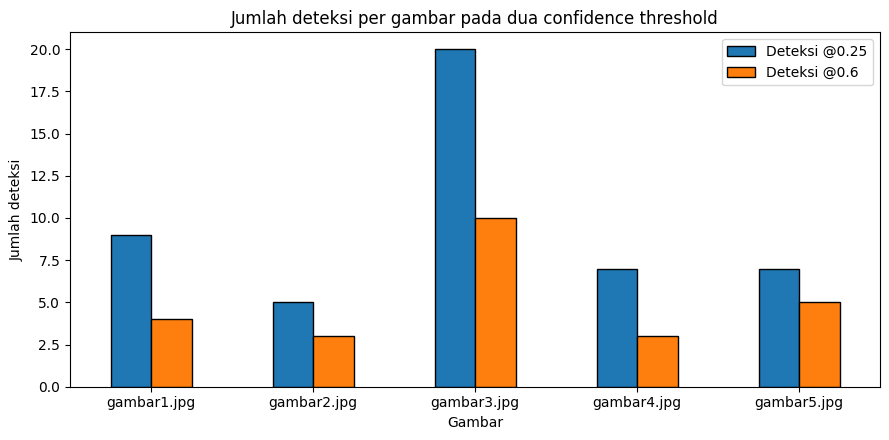

In [45]:
T_LOW, T_HIGH = THRESHOLDS
nama_gambar = sorted(hasil[T_LOW].keys())


def ringkas(nama):
    lo = df[(df.gambar == nama) & (df.threshold == T_LOW)]
    hi = df[(df.gambar == nama) & (df.threshold == T_HIGH)]
    kelas_hilang = sorted(set(lo.kelas) - set(hi.kelas))
    return {
        "Gambar": nama,
        f"Deteksi @{T_LOW}": len(lo),
        f"Deteksi @{T_HIGH}": len(hi),
        "Hilang": len(lo) - len(hi),
        "% Hilang": round(100 * (len(lo) - len(hi)) / len(lo), 1) if len(lo) else 0.0,
        f"Rata2 conf @{T_LOW}": round(lo.conf.mean(), 3) if len(lo) else np.nan,
        f"Rata2 conf @{T_HIGH}": round(hi.conf.mean(), 3) if len(hi) else np.nan,
        "Kelas yang hilang total": ", ".join(kelas_hilang) if kelas_hilang else "-",
    }


tabel = pd.DataFrame([ringkas(n) for n in nama_gambar])

total_lo, total_hi = tabel[f"Deteksi @{T_LOW}"].sum(), tabel[f"Deteksi @{T_HIGH}"].sum()
print(f"TOTAL: {total_lo} deteksi @{T_LOW}  ->  {total_hi} deteksi @{T_HIGH}  "
      f"({total_lo - total_hi} hilang, {100 * (total_lo - total_hi) / max(total_lo, 1):.1f}%)\n")
display(tabel)

ax = tabel.set_index("Gambar")[[f"Deteksi @{T_LOW}", f"Deteksi @{T_HIGH}"]].plot(
    kind="bar", figsize=(9, 4.5), edgecolor="black")
ax.set_ylabel("Jumlah deteksi")
ax.set_title("Jumlah deteksi per gambar pada dua confidence threshold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "jumlah_deteksi_per_gambar.png"), dpi=130)
plt.show()

## Step 9 - Deteksi yang tereliminasi dan distribusi confidence

,gambar,kelas,conf,kelas_ada_di_GT
0,gambar1.jpg,oven,0.563,True
1,gambar1.jpg,bowl,0.479,True
2,gambar1.jpg,potted plant,0.341,False
3,gambar1.jpg,person,0.278,True
4,gambar1.jpg,cup,0.276,True
5,gambar2.jpg,remote,0.489,True
6,gambar2.jpg,couch,0.453,True
7,gambar3.jpg,person,0.562,True
8,gambar3.jpg,car,0.418,True
9,gambar3.jpg,car,0.397,True


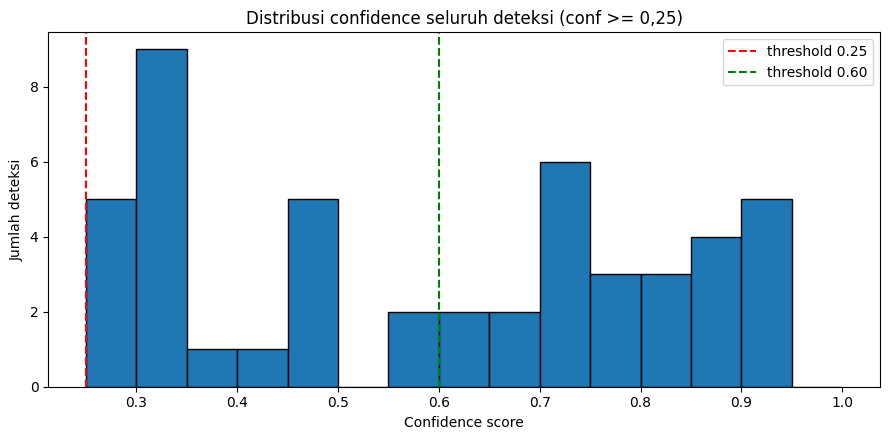

In [46]:
dropped = df[(df.threshold == T_LOW) & (df.conf < T_HIGH)].copy()

if dropped.empty:
    print("Tidak ada deteksi yang tereliminasi.")
else:
    dropped["kelas_ada_di_GT"] = dropped.apply(
        lambda r: r.kelas in GROUND_TRUTH.get(r.gambar, {}), axis=1)
    display(dropped[["gambar", "kelas", "conf", "kelas_ada_di_GT"]]
            .sort_values(["gambar", "conf"], ascending=[True, False])
            .reset_index(drop=True))

d = df[df.threshold == T_LOW]
plt.figure(figsize=(9, 4.5))
plt.hist(d.conf, bins=np.arange(T_LOW, 1.0001, 0.05), edgecolor="black")
for t, w in zip(THRESHOLDS, ["red", "green"]):
    plt.axvline(t, color=w, linestyle="--", label=f"threshold {t:.2f}")
plt.xlabel("Confidence score")
plt.ylabel("Jumlah deteksi")
plt.title("Distribusi confidence seluruh deteksi (conf >= 0,25)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "distribusi_confidence.png"), dpi=130)
plt.show()

## Step 10 - Evaluasi terhadap ground truth (level jumlah per kelas)

Dengan ground truth dari Step 3.4, tiap threshold dihitung:

- **TP** = min(jumlah prediksi kelas k, jumlah sebenarnya kelas k), dijumlahkan semua kelas
- **FP** = prediksi berlebih (termasuk kelas yang tidak ada di gambar)
- **FN** = objek sebenarnya yang tidak tertangkap
- **Precision** = TP/(TP+FP), **Recall** = TP/(TP+FN), **F1** = 2TP/(2TP+FP+FN)

> **Keterbatasan metode:** pencocokan dilakukan pada level **jumlah per kelas**, tanpa memeriksa posisi (IoU) box. Jadi ini estimasi kasar, bukan mAP. Sebut ini di laporan; jangan menyebutnya "akurasi model". Hasilnya juga hanya sebaik ground truth manual di Step 3.4.

Per gambar:


,Gambar,Threshold,TP,FP,FN,Precision,Recall,F1,Kelas di luar GT
0,gambar1.jpg,0.25,6,3,2,0.667,0.750,0.706,potted plant
1,gambar2.jpg,0.25,5,0,0,1.000,1.000,1.000,-
2,gambar3.jpg,0.25,15,5,0,0.750,1.000,0.857,-
3,gambar4.jpg,0.25,6,1,1,0.857,0.857,0.857,chair
4,gambar5.jpg,0.25,6,1,0,0.857,1.000,0.923,sports ball
5,gambar1.jpg,0.60,4,0,4,1.000,0.500,0.667,-
6,gambar2.jpg,0.60,3,0,2,1.000,0.600,0.750,-
7,gambar3.jpg,0.60,10,0,5,1.000,0.667,0.800,-
8,gambar4.jpg,0.60,3,0,4,1.000,0.429,0.600,-
9,gambar5.jpg,0.60,5,0,1,1.000,0.833,0.909,-


Agregat seluruh gambar (micro-average):


,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.25,38,10,3,0.792,0.927,0.854
1,0.60,25,0,16,1.000,0.610,0.758


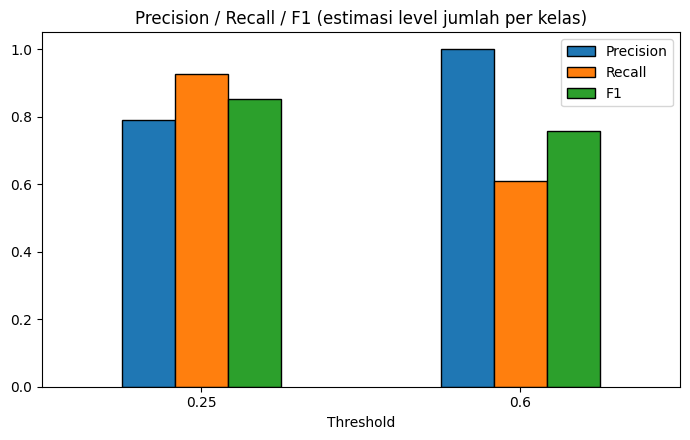

In [47]:
def metrik(df_thr, gt):
    pred = df_thr.groupby("kelas").size().to_dict()
    tp = fp = fn = 0
    for k in set(pred) | set(gt):
        p, g = pred.get(k, 0), gt.get(k, 0)
        m = min(p, g)
        tp += m
        fp += p - m
        fn += g - m
    prec = tp / (tp + fp) if (tp + fp) else np.nan
    rec = tp / (tp + fn) if (tp + fn) else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan
    kelas_asing = sorted(set(pred) - set(gt))
    return tp, fp, fn, prec, rec, f1, kelas_asing


baris_eval = []
for thr in THRESHOLDS:
    for nama in nama_gambar:
        tp, fp, fn, prec, rec, f1, asing = metrik(
            df[(df.gambar == nama) & (df.threshold == thr)], GROUND_TRUTH[nama])
        baris_eval.append({"Gambar": nama, "Threshold": thr, "TP": tp, "FP": fp, "FN": fn,
                           "Precision": prec, "Recall": rec, "F1": f1,
                           "Kelas di luar GT": ", ".join(asing) if asing else "-"})

eval_df = pd.DataFrame(baris_eval)

agregat = []
for thr in THRESHOLDS:
    s = eval_df[eval_df.Threshold == thr]
    tp, fp, fn = s.TP.sum(), s.FP.sum(), s.FN.sum()
    agregat.append({"Threshold": thr, "TP": tp, "FP": fp, "FN": fn,
                    "Precision": tp / (tp + fp) if (tp + fp) else np.nan,
                    "Recall": tp / (tp + fn) if (tp + fn) else np.nan,
                    "F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan})
agregat_df = pd.DataFrame(agregat)

print("Per gambar:")
display(eval_df.round(3))
print("Agregat seluruh gambar (micro-average):")
display(agregat_df.round(3))

ax = agregat_df.set_index("Threshold")[["Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(7, 4.5), edgecolor="black")
ax.set_ylim(0, 1.05)
ax.set_title("Precision / Recall / F1 (estimasi level jumlah per kelas)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "precision_recall_f1.png"), dpi=130)
plt.show()

## Step 11 - Analisis dan pembahasan

### A. Ringkasan kuantitatif

Menaikkan threshold dari 0,25 ke 0,60 mengurangi total deteksi dari **48 menjadi 25** (23 hilang, **47,9%**). Penurunan terjadi pada semua gambar, tetapi besarnya berbeda:

| Gambar | Deteksi 0,25 → 0,60 | % hilang |
|---|---|---|
| gambar4 (meja kerja) | 7 → 3 | 57,1% |
| gambar1 (dapur) | 9 → 4 | 55,6% |
| gambar3 (jalan kota) | 20 → 10 | 50,0% |
| gambar2 (dua kucing) | 5 → 3 | 40,0% |
| gambar5 (lapangan bisbol) | 7 → 5 | 28,6% |

`gambar5` paling stabil karena objek utamanya (empat person berukuran besar di latar rumput yang seragam) memiliki confidence 0,89-0,91, jauh di atas kedua threshold. Yang hilang hanya person kecil yang terpotong di sudut kiri bawah (0,457) dan *sports ball* (0,310). Sebaliknya, `gambar4` dan `gambar1` paling terdampak karena banyak objeknya berada pada confidence menengah (0,28-0,56): objek saling bertumpuk, terhalang, atau berkontras rendah.

Rata-rata confidence naik pada semua gambar (misalnya `gambar1` 0,561 → 0,778; `gambar3` 0,554 → 0,764; `gambar4` 0,553 → 0,781). **Ini bukan berarti model menjadi lebih yakin**, melainkan efek seleksi: deteksi berconfidence rendah dibuang sehingga rata-rata sisa otomatis naik. Seluruh deteksi pada 0,60 juga merupakan himpunan bagian dari deteksi pada 0,25, karena model dan NMS yang dipakai sama.

Histogram confidence (Step 9) berbentuk dua kelompok: 21 deteksi pada rentang 0,25-0,50 dan 27 deteksi pada ≥0,55, dengan jeda kosong pada 0,50-0,55.

### B. False positive pada conf 0,25 dan yang tereliminasi di 0,60

Pada conf 0,25 terdapat **10 false positive** dari 48 deteksi (precision 0,792). Pada conf 0,60 jumlahnya **nol** (precision 1,000): ke-25 deteksi yang bertahan seluruhnya sesuai ground truth. False positive pada 0,25 tersebar sebagai berikut:

- **gambar1 (3 FP):** `potted plant` 0,341, yaitu seikat daun herbal yang digantung di sudut kiri atas dikenali sebagai tanaman pot (warna dan bentuk dedaunan mirip, tetapi tidak ada pot); satu `bowl` berlebih (0,479); dan satu `person` berlebih (0,278).
- **gambar3 (5 FP):** dua `traffic light` berlebih (0,329 / 0,303 / 0,261; hanya satu yang benar menurut ground truth) yang berasal dari titik cahaya lampu kota yang buram (*bokeh*); `backpack` kedua 0,300 yang menduplikasi tas yang sebenarnya; dan dua person/mobil berlebih pada latar belakang yang buram.
- **gambar4 (1 FP):** `chair` 0,336.
- **gambar5 (1 FP):** `sports ball` 0,310, objek terang berukuran kecil di dekat anak yang membungkuk; tidak ada bola pada ground truth.

Sebagian besar false positive berconfidence **di bawah 0,35**, sehingga threshold 0,60 sangat efektif membuangnya. Namun confidence rendah **tidak identik dengan salah**: tas punggung yang benar pada `gambar3` hanya bernilai 0,343, praktis sama dengan `potted plant` yang salah (0,341), dan `cup` yang benar pada `gambar1` bernilai 0,276. Karena rentang confidence benar dan salah saling tumpang tindih di 0,26-0,35, tidak ada threshold yang memisahkan keduanya secara bersih.

### C. False negative baru (objek benar yang ikut hilang)

Harga dari threshold tinggi lebih besar daripada keuntungannya pada data ini. Naik ke 0,60 membuang 10 false positive, tetapi juga **13 objek yang benar**: TP turun **38 → 25**, FN naik **3 → 16**, dan recall turun **0,927 → 0,610** (Step 10). Rinciannya:

- **gambar1 (2):** `oven` 0,563 (kompor yang gelap dan tertutup peralatan) dan `cup` 0,276.
- **gambar2 (2):** `remote` 0,489 (remote kedua yang separuh tertutup tubuh kucing) dan `couch` 0,453 (sofa yang hampir seluruhnya tertutup selimut pink dan kucing). Recall gambar ini turun dari 1,00 (5/5) menjadi 0,60 (3/5).
- **gambar3 (5):** `backpack` 0,343 (objek utama di latar depan; cahaya senja yang redup dan warna tas yang mendekati warna sweater), satu `traffic light`, dan tiga person/mobil pada latar belakang yang buram.
- **gambar4 (3):** `tv` 0,496 (monitor di latar belakang yang terlalu terang dan terpotong tepi atas gambar) dan dua `keyboard` (0,349 / 0,347).
- **gambar5 (1):** `person` 0,457 (kepala anak yang terpotong tepi kiri bawah).

Ciri objek yang hilang: **terhalang atau terpotong** (remote, person), **ambigu secara visual** (couch, oven, tv, keyboard), **berkontras rendah** (backpack), dan **kecil serta buram di latar belakang** (person/mobil di gambar3). Per gambar, recall pada 0,60 turun menjadi 0,50 (gambar1), 0,60 (gambar2), 0,67 (gambar3), 0,43 (gambar4), dan 0,83 (gambar5).

### D. Kegagalan yang tidak tertolong threshold

Pada conf 0,25 hanya tersisa **3 objek yang tidak terdeteksi sama sekali** (FN = 3), sehingga menurunkan threshold lebih jauh pun tidak akan memperbaikinya:

- **gambar1:** `sink` dan `dining table`. Meja kayu penuh barang dan terlihat dari sudut miring, sedangkan wastafel hanya tampak sebagian di tepi kanan.
- **gambar4:** `cell phone`: kecil, berwarna gelap di atas meja gelap, dan berkontras rendah.

Polanya konsisten: objek **kecil, terhalang, atau berkontras rendah**. Penyebab yang masuk akal adalah kapasitas model *nano* (varian terkecil) yang terbatas, serta pengecilan `gambar3` dan `gambar4` dari 1280 px ke 640 px (`imgsz=640`) yang membuang detail objek kecil. Tidak ada deteksi salah dengan confidence ≥0,60 pada percobaan ini.

### E. Pengaruh karakteristik gambar

| Gambar | Rata-rata conf @0,25 | Rata-rata conf @0,60 | F1 @0,25 | F1 @0,60 | Karakter |
|---|---|---|---|---|---|
| gambar5 | 0,725 | 0,862 | 0,923 | 0,909 | Sedikit objek, besar, kontras jelas, cahaya baik |
| gambar2 | 0,695 | 0,844 | 1,000 | 0,750 | Dua objek utama besar, tetapi sofa/remote tertutup |
| gambar4 | 0,553 | 0,781 | 0,857 | 0,600 | Latar putih terang, objek bertumpuk (laptop, keyboard, monitor) |
| gambar1 | 0,561 | 0,778 | 0,706 | 0,667 | Remang, banyak objek kecil dan perabot bertumpuk |
| gambar3 | 0,554 | 0,764 | 0,857 | 0,800 | Terpadat (20 deteksi), cahaya senja, latar buram |

Gambar dengan objek besar, terpisah, dan tercahayai baik (`gambar5`, `gambar2`) menghasilkan confidence tertinggi dan paling sedikit kehilangan deteksi. Gambar yang padat, remang, atau penuh objek bertumpuk (`gambar3`, `gambar1`, `gambar4`) menghasilkan banyak deteksi berconfidence menengah-rendah, sehingga paling sensitif terhadap pilihan threshold. F1 pada 0,25 **lebih tinggi atau sama di kelima gambar**, bukan hanya pada agregat. Dengan hanya 5 gambar, ini pola, bukan hubungan sebab-akibat. Confidence tinggi pada `gambar5` juga tidak bisa dipisahkan dari kemungkinan kebocoran data (gambar ini dari `train2017`).

### F. Kesimpulan dan rekomendasi threshold

| | Precision | Recall | F1 | TP / FP / FN |
|---|---|---|---|---|
| conf 0,25 | 0,792 | 0,927 | 0,854 | 38 / 10 / 3 |
| conf 0,60 | 1,000 | 0,610 | 0,758 | 25 / 0 / 16 |

Pada dataset ini, **conf 0,25 memberikan hasil yang lebih baik secara keseluruhan**: recall dan F1 lebih tinggi (0,927 vs 0,610; 0,854 vs 0,758), dan keunggulan F1 itu konsisten di kelima gambar. Conf 0,60 unggul **hanya pada precision** (1,000 vs 0,792), tetapi dibayar mahal: ia membuang 10 false positive dengan harga 13 objek yang benar, dan melewatkan sekitar 39% dari seluruh objek pada ground truth. Istilah yang tepat bukan "0,25 lebih akurat", melainkan **0,25 menangkap lebih banyak objek benar dengan sedikit false positive tambahan, sedangkan 0,60 sangat bersih tetapi terlalu ketat**.

Penyebabnya ada pada karakter dataset. Banyak objek yang benar tetapi sulit (terhalang, terpotong, remang, kecil di latar belakang) memiliki confidence menengah 0,26-0,56, sehingga threshold 0,60 ikut membuangnya. Sementara itu false positive pada percobaan ini relatif sedikit.

**Hasil ini tidak boleh digeneralisasi.** Pada gambar lain yang mengandung banyak tekstur atau bentuk pengecoh (dedaunan, lampu bokeh, pola berulang), jumlah false positive pada 0,25 bisa jauh lebih besar, seperti yang sudah terlihat pada `potted plant` (herbal gantung) dan `traffic light` (bokeh). Rekomendasi praktis:

- **conf 0,25** cocok bila **objek yang terlewat lebih mahal** daripada alarm palsu, misalnya pemantauan atau pencarian objek yang hasilnya diverifikasi manusia, serta pada scene yang sulit seperti dataset ini.
- **conf 0,60** cocok bila **alarm palsu lebih mahal**, misalnya pelabelan atau penghitungan otomatis tanpa pengawasan, dengan konsekuensi menerima recall yang rendah.
- Nilai menengah (sekitar 0,35-0,45) layak diuji pada penelitian lanjutan sebagai kompromi, di luar dua threshold yang diminta tugas ini.

### G. Keterbatasan penelitian

1. **Hanya 5 gambar dan satu model** (`yolov8n`, varian terkecil), dengan satu kali run dan hanya dua titik threshold. Kesimpulan "0,25 lebih baik" berlaku untuk dataset ini saja.
2. **Ground truth manual yang direvisi setelah melihat hasil deteksi.** Ini berisiko bias (hasil model memengaruhi cara kita menghitung objek). Hitungan person (7) dan mobil (5) pada latar belakang `gambar3` yang buram bergantung pada penilaian visual dan sangat menentukan angka precision/recall gambar tersebut. `baseball bat` (gambar5) dan `truck` (gambar3) tidak dimasukkan ke ground truth.
3. **Evaluasi level jumlah per kelas**, bukan IoU/mAP: posisi box tidak diperiksa, sehingga box yang salah tempat tetapi kelasnya benar tetap dihitung benar.
4. **Kebocoran data pada `gambar5`**: gambar berasal dari `train2017`, bagian data yang dipakai melatih model, sehingga confidence-nya berpotensi terlalu optimistis.
5. **Sumber gambar:** gambar berasal dari internet (COCO dan Unsplash), bukan foto sendiri sebagaimana ketentuan tugas.
6. **Waktu proses 12,4 dtk vs 0,1 dtk** pada Step 5 bukan efek threshold, melainkan inisialisasi pada run pertama; jangan ditafsirkan sebagai perbedaan kecepatan.
7. `iou` (NMS) dan `imgsz` dikunci (0,7 dan 640); pengaruh keduanya tidak diuji.

## Step 12 - Ekspor hasil

Simpan tabel ke CSV dan kompres seluruh keluaran (gambar hasil kedua threshold, grafik, CSV) menjadi satu ZIP untuk dilampirkan ke laporan.

In [48]:
df.to_csv(os.path.join(OUT_DIR, "semua_deteksi.csv"), index=False)
tabel.to_csv(os.path.join(OUT_DIR, "perbandingan_per_gambar.csv"), index=False)
eval_df.to_csv(os.path.join(OUT_DIR, "evaluasi_per_gambar.csv"), index=False)
agregat_df.to_csv(os.path.join(OUT_DIR, "evaluasi_agregat.csv"), index=False)

zip_path = shutil.make_archive(f"hasil_{NIM}", "zip", OUT_DIR)
print("ZIP dibuat:", zip_path)

from google.colab import files
files.download(zip_path)

ZIP dibuat: /content/hasil_235150201111074.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Referensi dan sumber

**Materi kuliah**
- Sari, Y. A. (2025). *YOLO* [Slide kuliah]. CIF61339 Pengolahan Citra Digital dan Visi Komputer, Fakultas Ilmu Komputer, Universitas Brawijaya. Versi dokumen 2 Juli 2025.

**Model dan library**
- Redmon, J., Divvala, S., Girshick, R., & Farhadi, A. (2016). You Only Look Once: Unified, Real-Time Object Detection. *IEEE CVPR 2016*.
- Jocher, G., Chaurasia, A., & Qiu, J. (2023). *Ultralytics YOLOv8*. https://github.com/ultralytics/ultralytics (lisensi AGPL-3.0). Dokumentasi: https://docs.ultralytics.com

**Dataset dan gambar**
- Lin, T.-Y., dkk. (2014). Microsoft COCO: Common Objects in Context. *ECCV 2014*. https://cocodataset.org
  - `gambar1.jpg`: http://images.cocodataset.org/val2017/000000397133.jpg
  - `gambar2.jpg`: http://images.cocodataset.org/val2017/000000039769.jpg
  - `gambar5.jpg`: http://images.cocodataset.org/train2017/000000411975.jpg
- Unsplash (Unsplash License), nama fotografer **dilengkapi dari halaman foto masing-masing**:
  - `gambar3.jpg`: https://images.unsplash.com/photo-1458169495136-854e4c39548a
  - `gambar4.jpg`: https://images.unsplash.com/photo-1498050108023-c5249f4df085

*Ganti bagian "Dataset dan gambar" bila memakai foto sendiri: cukup tulis perangkat dan tanggal pengambilan.*